# Машинное обучение-2: Глубокое обучение, РЭШ

## Домашнее задание 1. Введение в PyTorch. Полносвязные нейронные сети.

### Общая информация

Дата выдачи: 31.03.2026

Жесткий дедлайн: 23:59MSK 07.04.2026

### Оценивание и штрафы
Максимально допустимая оценка за работу — 10 баллов. Сдавать задание после жёсткого дедлайна сдачи нельзя.

Итогова оценка считается как
$$
min(task_1, task_2)*0.8 + max(task_1, task_2)*0.2
$$

где task_1 и task_2 - оценки за первое и второе заданиее соответсвенно.
Также, за домашнее задание выставляется 0, если не сделано нулевое или третье задание.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.
Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### О задании

В этом задании вам предстоит предсказывать год выпуска песни (**задача регрессии**) по некоторым звуковым признакам: [данные](https://archive.ics.uci.edu/ml/datasets/yearpredictionmsd). В ячейках ниже находится код для загрузки данных. Обратите внимание, что обучающая и тестовая выборки располагаются в одном файле, поэтому НЕ меняйте ячейку, в которой производится деление данных.

In [65]:
import torch
from torch import nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import random
device = "cuda" if torch.cuda.is_available() else "cpu"
from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt

In [66]:
!wget -O data.txt.zip https://archive.ics.uci.edu/ml/machine-learning-databases/00203/YearPredictionMSD.txt.zip

--2026-04-06 19:50:18--  https://archive.ics.uci.edu/ml/machine-learning-databases/00203/YearPredictionMSD.txt.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘data.txt.zip’

data.txt.zip            [             <=>    ] 201.24M  2.40MB/s    in 87s     

2026-04-06 19:51:47 (2.32 MB/s) - ‘data.txt.zip’ saved [211011981]



In [67]:
df = pd.read_csv('data.txt.zip', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


Мы вывели кусок данных, чтобы понять, насколько они пригодны для работы без изменений. Здесь ясно, что сомнительно дальше с такими данными работать, потому что как минимум есть отрицательные значения, которые не отмасштабированы, кроме того еще сразу бросается в глаза совсем разная размерность, где-то видим реально большие числа, а где-то 0.075. Ясно, что будем скейлить.

In [68]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

train_size = 463715
X_train = X[:train_size, :]
y_train = y[:train_size]
X_test = X[train_size:, :]
y_test = y[train_size:]

## Задание 0. (0 баллов, но при невыполнении максимум за все задание &mdash; 0 баллов)

Мы будем использовать RMSE как метрику качества. Для самого первого бейзлайна обучите `Ridge` регрессию из `sklearn`. Кроме того, посчитайте качество при наилучшем константном прогнозе.

Для выполнения данного задания (и всех последующих) предобработайте данные.

1. Зафиксируйте random_seed везде где только возможно. Вам предоставлена функция для этого, однако вы можете дополнить ее своими дополнениями
2. Обучите StandertScaler и предобработайте ваши данные. В следующих заданиях можете использовать другой scaler или вообще отказаться от него


In [69]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler()
y_scaler = StandardScaler()



In [ ]:
def set_random_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)



In [71]:
set_random_seed(42)

In [72]:
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)



In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error

model = Ridge()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
rmse_for_model = root_mean_squared_error(y_test, y_pred)
print(f'RMSE for Ridge: {rmse_for_model}:.4f')

RMSE for Ridge: 9.510160820470432


Лучшая константа для RMSE это среднее, посчитаем значение метрики при нем

In [ ]:
best_rmse_metric = root_mean_squared_error(y_test, [y_test.mean()] * len(y_test))
print(f'Best constant RMSE: {best_rmse_metric}:.4f')

Best constant RMSE: 10.851909820717683


## Задание 1. (максимум 10 баллов)

Закрепите свои знания о том, как pytorch работает с обратным распространением ошибки, проделав следующие шаги:

1. Создайте модель линейной регрессии, которая будет состоять только из одного Linear слоя.
2. Напишите цикл обучения вашей линейной регрессии. В нем реализуйте подсчет функции потерь, сделайте шаг градиентного спуска. Запрещено использовать готовые оптимизаторы и loss-функции из библиотеки pytorch. Для подсчета градиента воспользуйтесь методом backward.
3. Запустите обучение на 10 эпохах, после каждой проверяйте значение целевой метрики на тестовой выборке.
4. Выведите на экран графики метрики и значения функции потерь на тестовой и обучающей выборке.

В данном задании нет цели побить какой-то порог по метрике. Ваша задача - убедиться в том, что ваш рукописный цикл обучения работает. Для ускорения вычислений и обучения модели можете брать только срез данных, а не весь датасет.

In [75]:
# ⸂⸂⸜(രᴗര๑)⸝⸃⸃ Good luck!

X_train_torch = torch.FloatTensor(X_train_scaled)
y_train_torch = torch.FloatTensor(y_train).reshape(-1, 1)

X_test_torch = torch.FloatTensor(X_test_scaled)
y_test_torch = torch.FloatTensor(y_test).reshape(-1, 1)

w = torch.randn(X_train_torch.shape[1], 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

lr = 0.01

train_loss = []
test_loss = []

for epoch in range(10):

  y_hat = X_train_torch @ w + b
  loss = torch.sqrt(torch.mean((y_train_torch - y_hat) ** 2))

  loss.backward()

  with torch.no_grad():
    y_pred = X_test_torch @ w + b
    test_rmse = torch.sqrt(torch.mean((y_test_torch - y_pred) ** 2))

    w -= lr * w.grad
    b -= lr * b.grad

    w.grad.zero_()
    b.grad.zero_()

  train_loss.append(loss.item())
  test_loss.append(test_rmse.item())

  print(f'{epoch} iteration train RMSE: {loss.item():.4f}')
  print(f'{epoch} iteration test RMSE: {test_rmse.item():.4f}')

0 iteration train RMSE: 1999.3589
0 iteration test RMSE: 1999.5511
1 iteration train RMSE: 1999.3489
1 iteration test RMSE: 1999.5411
2 iteration train RMSE: 1999.3390
2 iteration test RMSE: 1999.5312
3 iteration train RMSE: 1999.3290
3 iteration test RMSE: 1999.5212
4 iteration train RMSE: 1999.3188
4 iteration test RMSE: 1999.5112
5 iteration train RMSE: 1999.3088
5 iteration test RMSE: 1999.5012
6 iteration train RMSE: 1999.2988
6 iteration test RMSE: 1999.4911
7 iteration train RMSE: 1999.2889
7 iteration test RMSE: 1999.4812
8 iteration train RMSE: 1999.2789
8 iteration test RMSE: 1999.4712
9 iteration train RMSE: 1999.2690
9 iteration test RMSE: 1999.4612


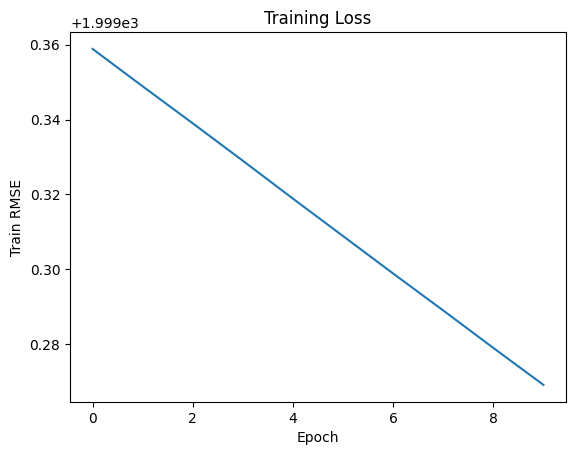

In [76]:
plt.figure()
plt.plot(train_loss)
plt.xlabel('Epoch')
plt.ylabel('Train RMSE')
plt.title('Training Loss')
plt.show()

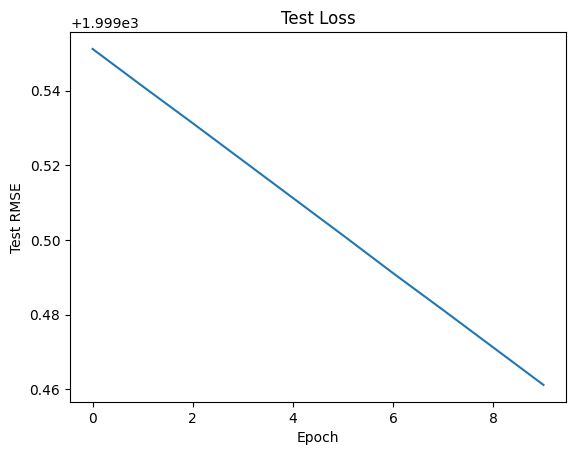

In [77]:
plt.figure()
plt.plot(test_loss)
plt.xlabel('Epoch')
plt.ylabel('Test RMSE')
plt.title('Test Loss')
plt.show()

In [78]:
y_test

array([2007, 2003, 2005, ..., 2006, 2006, 2005], shape=(51630,))

## Задание 2. (максимум 10 баллов)

Реализуйте обучение и тестирование нейронной сети для предоставленного вам набора данных. Соотношение между полученным значением метрики на тестовой выборке и баллами за задание следующее:

- $\text{RMSE} \le 9.00 $ &mdash; 4 балла
- $\text{RMSE} \le 8.90 $ &mdash; 6 баллов
- $\text{RMSE} \le 8.80 $ &mdash; 8 баллов
- $\text{RMSE} \le 8.75 $ &mdash; 10 баллов

Есть несколько правил, которых вам нужно придерживаться:

- Весь пайплайн обучения должен быть написан на PyTorch. При этом вы можете пользоваться другими библиотеками (`numpy`, `sklearn` и пр.), но только для обработки данных. То есть как угодно трансформировать данные и считать метрики с помощью этих библиотек можно, а импортировать модели из `sklearn` и выбивать с их помощью требуемое качество &mdash; нельзя. Также нельзя пользоваться библиотеками, для которых сам PyTorch является зависимостью.

- Мы никак не ограничиваем ваш выбор архитектуры модели, но скорее всего вам будет достаточно полносвязной нейронной сети.

- Для обучения запрещается использовать какие-либо иные данные, кроме обучающей выборки.

- Ансамблирование моделей запрещено.

### Полезные советы:

- Очень вряд ли, что у вас с первого раза получится выбить качество на 10 баллов, поэтому пробуйте разные архитектуры, оптимизаторы и значения гиперпараметров. В идеале при запуске каждого нового эксперимента вы должны менять что-то одно, чтобы точно знать, как этот фактор влияет на качество.

- Не забудьте, что для улучшения качества модели вам поможет **нормировка таргета**.

- Тот факт, что мы занимаемся глубинным обучением, не означает, что стоит забывать про приемы, использующиеся в классическом машинном обучении. Так что обязательно проводите исследовательский анализ данных, отрисовывайте нужные графики и не забывайте про масштабирование и подбор гиперпараметров.

- Вы наверняка столкнетесь с тем, что ваша нейронная сеть будет сильно переобучаться. Для нейросетей существуют специальные методы регуляризации, например, dropout ([статья](https://jmlr.org/papers/volume15/srivastava14a/srivastava14a.pdf)) и weight decay ([блогпост](https://towardsdatascience.com/weight-decay-l2-regularization-90a9e17713cd)). Они, разумеется, реализованы в PyTorch. Попробуйте поэкспериментировать с ними.

- Если вы чего-то не знаете, не гнушайтесь гуглить. В интернете очень много полезной информации, туториалов и советов по глубинному обучению в целом и по PyTorch в частности. Но не забывайте, что за скатанный код без ссылки на источник придется ответить по всей строгости!

- Если вы сразу реализуете обучение на GPU, то у вас будет больше времени на эксперименты, так как любые вычисления будут работать быстрее. Google Colab предоставляет несколько GPU-часов (обычно около 8-10) в сутки бесплатно.

- Чтобы отладить код, можете обучаться на небольшой части данных или даже на одном батче. Если лосс на обучающей выборке не падает, то что-то точно идет не так!

- Пользуйтесь утилитами, которые вам предоставляет PyTorch (например, Dataset и Dataloader). Их специально разработали для упрощения разработки пайплайна обучения.

- Скорее всего вы захотите отслеживать прогресс обучения. Для создания прогресс-баров есть удобная библиотека `tqdm`.

- Быть может, вы захотите, чтобы графики рисовались прямо во время обучения. Можете воспользоваться функцией [clear_output](http://ipython.org/ipython-doc/dev/api/generated/IPython.display.html#IPython.display.clear_output), чтобы удалять старый график и рисовать новый на его месте.

**ОБЯЗАТЕЛЬНО** рисуйте графики зависимости лосса/метрики на обучающей и тестовой выборках в зависимости от времени обучения. Если обучение занимает относительно небольшое число эпох, то лучше рисовать зависимость от номера шага обучения, если же эпох больше, то рисуйте зависимость по эпохам. Если проверяющий не увидит такого графика для вашей лучшей модели, то он в праве снизить баллы за задание.

**ВАЖНО!** Ваше решение должно быть воспроизводимым. Если это не так, то проверяющий имеет право снизить баллы за задание. Чтобы зафиксировать random seed, воспользуйтесь функцией из предыдущего задания.



Вы можете придерживаться любой адекватной струкуры кода, но мы советуем воспользоваться сигнатурами функций, которые приведены ниже. Лучше всего, если вы проверите ваши предсказания ассертом: так вы убережете себя от разных косяков, например, что вектор предсказаний состоит из всего одного числа. В любом случае, внимательно следите за тем, для каких тензоров вы считаете метрику RMSE. При случайном или намеренном введении в заблуждение проверяющие очень сильно разозлятся.

In [123]:
import torch.optim as optim

set_random_seed(42)

y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).reshape(-1)
y_test_scaled = y_scaler.transform(y_test.reshape(-1, 1)).reshape(-1)

X_train_torch = torch.FloatTensor(X_train_scaled)
y_train_torch = torch.FloatTensor(y_train).reshape(-1, 1)
y_train_torch_scaled = torch.FloatTensor(y_train_scaled).reshape(-1, 1)

X_test_torch = torch.FloatTensor(X_test_scaled)
y_test_torch = torch.FloatTensor(y_test).reshape(-1, 1)
y_test_torch_scaled = torch.FloatTensor(y_test_scaled).reshape(-1, 1)

train_generator = torch.Generator().manual_seed(42)

train_set = torch.utils.data.TensorDataset(X_train_torch, y_train_torch_scaled)
train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size=1024,
    shuffle=True,
    generator=train_generator,
    num_workers=0,
)

test_set = torch.utils.data.TensorDataset(X_test_torch, y_test_torch_scaled)
test_loader = torch.utils.data.DataLoader(
    test_set,
    batch_size=1024,
    shuffle=False,
    num_workers=0,
)


def make_model(in_features):
    return nn.Sequential(
        nn.Linear(in_features, 64),
        nn.ReLU(),
        nn.Dropout(0.1),

        nn.Linear(64, 16),
        nn.ReLU(),

        nn.Linear(16, 1),
    ).to(device)


model = make_model(X_train_torch.shape[1])
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.SmoothL1Loss(beta=0.5)



In [124]:
def inverse_scale_target(values_1d):
    values_2d = values_1d.reshape(-1, 1)
    inv = y_scaler.inverse_transform(values_2d)
    return inv.reshape(-1)


def evaluate_rmse(model, loader):
    model.eval()
    preds_scaled = []
    targets_scaled = []

    with torch.no_grad():
        for x, y_scaled in loader:
            x = x.to(device)
            y_hat_scaled = model(x)
            preds_scaled.append(y_hat_scaled.cpu())
            targets_scaled.append(y_scaled.cpu())

    preds_scaled = torch.cat(preds_scaled).squeeze().numpy()
    targets_scaled = torch.cat(targets_scaled).squeeze().numpy()

    preds = inverse_scale_target(preds_scaled)
    targets = inverse_scale_target(targets_scaled)

    rmse = np.sqrt(np.mean((preds - targets) ** 2))
    return float(rmse), torch.FloatTensor(preds)


def train(model, optimizer, criterion, train_loader, test_loader=None, n_epochs=50):
    history = {"train_rmse": [], "test_rmse": []}

    for epoch in range(n_epochs):
        model.train()

        for x, y_scaled in train_loader:
            x = x.to(device)
            y_scaled = y_scaled.to(device)

            y_hat_scaled = model(x)
            loss = criterion(y_hat_scaled, y_scaled)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_rmse, _ = evaluate_rmse(model, train_loader)
        history["train_rmse"].append(train_rmse)

        if test_loader is not None:
            test_rmse, _ = evaluate_rmse(model, test_loader)
            history["test_rmse"].append(test_rmse)
            print(
                f"Epoch [{epoch+1}/{n_epochs}] train RMSE: {train_rmse:.4f} | "
                f"test RMSE: {test_rmse:.4f}"
            )
        else:
            print(f"Epoch [{epoch+1}/{n_epochs}] train RMSE: {train_rmse:.4f}")

    return history


def test(model, test_loader):
    rmse, predicts = evaluate_rmse(model, test_loader)
    print(f"Test RMSE: {rmse:.4f}")
    return predicts



In [126]:
history = train(
    model,
    optimizer,
    criterion,
    train_loader,
    test_loader=test_loader,
    n_epochs=30,
)
preds = test(model, test_loader)
assert preds.shape[0] == y_test.shape[0]



Epoch [1/30] train RMSE: 8.7026 | test RMSE: 9.0077
Epoch [2/30] train RMSE: 8.6821 | test RMSE: 9.0008
Epoch [3/30] train RMSE: 8.7286 | test RMSE: 9.0453
Epoch [4/30] train RMSE: 8.6964 | test RMSE: 9.0155
Epoch [5/30] train RMSE: 8.7156 | test RMSE: 9.0248
Epoch [6/30] train RMSE: 8.7127 | test RMSE: 9.0355
Epoch [7/30] train RMSE: 8.6669 | test RMSE: 8.9995
Epoch [8/30] train RMSE: 8.7065 | test RMSE: 9.0319
Epoch [9/30] train RMSE: 8.6930 | test RMSE: 9.0179
Epoch [10/30] train RMSE: 8.6360 | test RMSE: 8.9820
Epoch [11/30] train RMSE: 8.6481 | test RMSE: 8.9995
Epoch [12/30] train RMSE: 8.6793 | test RMSE: 9.0172
Epoch [13/30] train RMSE: 8.6707 | test RMSE: 9.0401
Epoch [14/30] train RMSE: 8.7000 | test RMSE: 9.0476
Epoch [15/30] train RMSE: 8.6726 | test RMSE: 9.0260
Epoch [16/30] train RMSE: 8.6443 | test RMSE: 9.0112
Epoch [17/30] train RMSE: 8.6425 | test RMSE: 9.0040
Epoch [18/30] train RMSE: 8.6267 | test RMSE: 9.0038
Epoch [19/30] train RMSE: 8.6521 | test RMSE: 9.0195
Ep

In [127]:
# ೭੧(❛〜❛✿)੭೨ Go forward!

def make_model(in_features):
    return nn.Sequential(

        nn.Linear(in_features, 64),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.Dropout(0.1),

        nn.Linear(64, 16),
        nn.ReLU(),

        nn.Linear(16, 1),
    ).to(device)


model = make_model(X_train_torch.shape[1])
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

history = train(
    model,
    optimizer,
    criterion,
    train_loader,
    test_loader=test_loader,
    n_epochs=30,
)
preds = test(model, test_loader)

Epoch [1/30] train RMSE: 8.8838 | test RMSE: 8.9831
Epoch [2/30] train RMSE: 8.7438 | test RMSE: 8.9022
Epoch [3/30] train RMSE: 8.6740 | test RMSE: 8.8475
Epoch [4/30] train RMSE: 8.6270 | test RMSE: 8.8124
Epoch [5/30] train RMSE: 8.6006 | test RMSE: 8.8027
Epoch [6/30] train RMSE: 8.5724 | test RMSE: 8.7970
Epoch [7/30] train RMSE: 8.5615 | test RMSE: 8.7848
Epoch [8/30] train RMSE: 8.5427 | test RMSE: 8.7844
Epoch [9/30] train RMSE: 8.5286 | test RMSE: 8.8098
Epoch [10/30] train RMSE: 8.5158 | test RMSE: 8.7873
Epoch [11/30] train RMSE: 8.5043 | test RMSE: 8.7994
Epoch [12/30] train RMSE: 8.4827 | test RMSE: 8.7779
Epoch [13/30] train RMSE: 8.4756 | test RMSE: 8.7839
Epoch [14/30] train RMSE: 8.4685 | test RMSE: 8.7787
Epoch [15/30] train RMSE: 8.4649 | test RMSE: 8.7967
Epoch [16/30] train RMSE: 8.4428 | test RMSE: 8.7981
Epoch [17/30] train RMSE: 8.4502 | test RMSE: 8.7827
Epoch [18/30] train RMSE: 8.4305 | test RMSE: 8.7932
Epoch [19/30] train RMSE: 8.4293 | test RMSE: 8.7919
Ep

In [128]:
# ೭੧(❛〜❛✿)੭೨ Go forward!

def make_model(in_features):
    return nn.Sequential(

        nn.Linear(in_features, 64),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.Dropout(0.1),

        nn.Linear(64, 16),
        nn.BatchNorm1d(16),
        nn.ReLU(),

        nn.Linear(16, 1),
    ).to(device)


model = make_model(X_train_torch.shape[1])
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

history = train(
    model,
    optimizer,
    criterion,
    train_loader,
    test_loader=test_loader,
    n_epochs=30,
)
preds = test(model, test_loader)

Epoch [1/30] train RMSE: 8.8389 | test RMSE: 8.9539
Epoch [2/30] train RMSE: 8.7416 | test RMSE: 8.8746
Epoch [3/30] train RMSE: 8.6754 | test RMSE: 8.8267
Epoch [4/30] train RMSE: 8.6373 | test RMSE: 8.8178
Epoch [5/30] train RMSE: 8.6028 | test RMSE: 8.7999
Epoch [6/30] train RMSE: 8.5835 | test RMSE: 8.7921
Epoch [7/30] train RMSE: 8.5737 | test RMSE: 8.7856
Epoch [8/30] train RMSE: 8.5406 | test RMSE: 8.7855
Epoch [9/30] train RMSE: 8.5293 | test RMSE: 8.7754
Epoch [10/30] train RMSE: 8.5200 | test RMSE: 8.7902
Epoch [11/30] train RMSE: 8.4985 | test RMSE: 8.7785
Epoch [12/30] train RMSE: 8.4856 | test RMSE: 8.7864
Epoch [13/30] train RMSE: 8.4754 | test RMSE: 8.7798
Epoch [14/30] train RMSE: 8.4675 | test RMSE: 8.7818
Epoch [15/30] train RMSE: 8.4601 | test RMSE: 8.7672
Epoch [16/30] train RMSE: 8.4547 | test RMSE: 8.7622
Epoch [17/30] train RMSE: 8.4493 | test RMSE: 8.7779
Epoch [18/30] train RMSE: 8.4340 | test RMSE: 8.7749
Epoch [19/30] train RMSE: 8.4332 | test RMSE: 8.7577
Ep

In [118]:
# ೭੧(❛〜❛✿)੭೨ Go forward!

def make_model(in_features):
    return nn.Sequential(

        nn.Linear(in_features, 64),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.Dropout(0.1),

        nn.Linear(64, 32),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.Dropout(0.1),

        nn.Linear(32, 16),
        nn.BatchNorm1d(16),
        nn.ReLU(),

        nn.Linear(16, 1),
    ).to(device)


model = make_model(X_train_torch.shape[1])
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

history = train(
    model,
    optimizer,
    criterion,
    train_loader,
    test_loader=test_loader,
    n_epochs=30,
)
preds = test(model, test_loader)

Epoch [1/30] train RMSE: 8.7659 | test RMSE: 8.9048
Epoch [2/30] train RMSE: 8.6811 | test RMSE: 8.8356
Epoch [3/30] train RMSE: 8.6207 | test RMSE: 8.8072
Epoch [4/30] train RMSE: 8.5914 | test RMSE: 8.8141
Epoch [5/30] train RMSE: 8.5502 | test RMSE: 8.8042
Epoch [6/30] train RMSE: 8.5389 | test RMSE: 8.7850
Epoch [7/30] train RMSE: 8.5091 | test RMSE: 8.8148
Epoch [8/30] train RMSE: 8.4773 | test RMSE: 8.8030
Epoch [9/30] train RMSE: 8.4683 | test RMSE: 8.7716
Epoch [10/30] train RMSE: 8.4712 | test RMSE: 8.7749
Epoch [11/30] train RMSE: 8.4660 | test RMSE: 8.7802
Epoch [12/30] train RMSE: 8.4484 | test RMSE: 8.7611
Epoch [13/30] train RMSE: 8.4334 | test RMSE: 8.7797
Epoch [14/30] train RMSE: 8.4242 | test RMSE: 8.7743
Epoch [15/30] train RMSE: 8.4155 | test RMSE: 8.7614
Epoch [16/30] train RMSE: 8.4092 | test RMSE: 8.7758
Epoch [17/30] train RMSE: 8.4037 | test RMSE: 8.7657
Epoch [18/30] train RMSE: 8.3934 | test RMSE: 8.7768
Epoch [19/30] train RMSE: 8.4054 | test RMSE: 8.7640
Ep

In [ ]:
# ೭੧(❛〜❛✿)੭೨ Go forward!

def make_model(in_features):
    return nn.Sequential(

        nn.Linear(in_features, 64),
        nn.GELU(),
        nn.Dropout(0.1),

        nn.Linear(64, 32),
        nn.GELU(),
        nn.Dropout(0.1),

        nn.Linear(32, 16),
        nn.GELU(),

        nn.Linear(16, 1),
    ).to(device)


model = make_model(X_train_torch.shape[1])
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

history = train(
    model,
    optimizer,
    criterion,
    train_loader,
    test_loader=test_loader,
    n_epochs=30,
)
preds = test(model, test_loader)

Epoch [1/30] train RMSE: 8.8023 | test RMSE: 8.9012
Epoch [2/30] train RMSE: 8.7159 | test RMSE: 8.8497
Epoch [3/30] train RMSE: 8.6520 | test RMSE: 8.8167
Epoch [4/30] train RMSE: 8.6115 | test RMSE: 8.8058
Epoch [5/30] train RMSE: 8.5787 | test RMSE: 8.7865
Epoch [6/30] train RMSE: 8.5442 | test RMSE: 8.7786
Epoch [7/30] train RMSE: 8.5167 | test RMSE: 8.7661
Epoch [8/30] train RMSE: 8.4944 | test RMSE: 8.7628
Epoch [9/30] train RMSE: 8.4802 | test RMSE: 8.7670
Epoch [10/30] train RMSE: 8.4564 | test RMSE: 8.7514
Epoch [11/30] train RMSE: 8.4349 | test RMSE: 8.7490
Epoch [12/30] train RMSE: 8.4266 | test RMSE: 8.7424
Epoch [13/30] train RMSE: 8.4085 | test RMSE: 8.7364
Epoch [14/30] train RMSE: 8.3956 | test RMSE: 8.7395
Epoch [15/30] train RMSE: 8.3843 | test RMSE: 8.7345
Epoch [16/30] train RMSE: 8.3682 | test RMSE: 8.7401
Epoch [17/30] train RMSE: 8.3663 | test RMSE: 8.7373
Epoch [18/30] train RMSE: 8.3472 | test RMSE: 8.7485
Epoch [19/30] train RMSE: 8.3416 | test RMSE: 8.7456
Ep

In [138]:
# ೭੧(❛〜❛✿)੭೨ Go forward!

def make_model(in_features):
    return nn.Sequential(

        nn.Linear(in_features, 128),
        nn.BatchNorm1d(128),
        nn.GELU(),
        nn.Dropout(0.2),

        nn.Linear(128, 64),
        nn.BatchNorm1d(64),
        nn.GELU(),
        nn.Dropout(0.2),

        nn.Linear(64, 16),
        nn.BatchNorm1d(16),
        nn.GELU(),
        nn.Dropout(0.1),

        nn.Linear(16, 1),
    ).to(device)


model = make_model(X_train_torch.shape[1])
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.MSELoss()

history = train(
    model,
    optimizer,
    criterion,
    train_loader,
    test_loader=test_loader,
    n_epochs=30,
)
preds = test(model, test_loader)

Epoch [1/30] train RMSE: 8.7761 | test RMSE: 8.9095
Epoch [2/30] train RMSE: 8.6771 | test RMSE: 8.8307
Epoch [3/30] train RMSE: 8.6163 | test RMSE: 8.7956
Epoch [4/30] train RMSE: 8.5680 | test RMSE: 8.7857
Epoch [5/30] train RMSE: 8.5357 | test RMSE: 8.7626
Epoch [6/30] train RMSE: 8.4833 | test RMSE: 8.7499
Epoch [7/30] train RMSE: 8.4667 | test RMSE: 8.7547
Epoch [8/30] train RMSE: 8.4482 | test RMSE: 8.7531
Epoch [9/30] train RMSE: 8.4200 | test RMSE: 8.7455
Epoch [10/30] train RMSE: 8.3915 | test RMSE: 8.7555
Epoch [11/30] train RMSE: 8.3758 | test RMSE: 8.7398
Epoch [12/30] train RMSE: 8.3585 | test RMSE: 8.7319
Epoch [13/30] train RMSE: 8.3483 | test RMSE: 8.7335
Epoch [14/30] train RMSE: 8.3116 | test RMSE: 8.7485
Epoch [15/30] train RMSE: 8.2908 | test RMSE: 8.7508
Epoch [16/30] train RMSE: 8.3012 | test RMSE: 8.7315
Epoch [17/30] train RMSE: 8.2819 | test RMSE: 8.7293
Epoch [18/30] train RMSE: 8.2665 | test RMSE: 8.7270
Epoch [19/30] train RMSE: 8.2528 | test RMSE: 8.7401
Ep

## Задание 3. (0 баллов, но при невыполнении максимум за все задание &mdash; 0 баллов)

Напишите небольшой отчет о том, как вы добились полученного качества: какие средства использовали и какие эксперименты проводили. Подробно расскажите об архитектурах и значениях гиперпараметров, а также какие метрики на тесте они показывали. Чтобы отчет был зачтен, необходимо привести хотя бы 3 эксперимента.

### Эксперименты:

- Сначала я пробовал BatchNorm и DropOut по отдельности. Убедившись в том, что оба сильно помогают справиться с переобучением, попробовал разные способы их комбинации. Комбинировал в разном порядке, убирал DropOut с последнего слоя, пока не нашёл в интернете, что лучше всего использовать FC -> BatchNorm -> Activation -> DropOut

- Постепенно менял архитектуру сети. Сначала подумал, что раз признаков всего 90, то стоит взять размер выхода первого слоя 64, постепенно уменьшая, так как в интернете написано, что для таблиц нет смысла идти на увеличение. Менял промежуточные размерности, но особого эффекта это не приносило, и модель переобучалась. Потом попробовал взять на первом слое 128, чтобы какие-то важные признаки не занулялись сразу, а находились. Чтобы модель не переобучалась, увеличил вероятность в DropOut. Это принесло свои плоды, и качество 8.75 пробито!

- На последнем шаге также поменял функцию активации с ReLU на GeLU. Справилась она намного лучще